In [1]:
from numpy.linalg import eig, inv, det
from numpy import shape, array, matmul, eye

1) Kinematics Matrix

In [2]:
A = array([[1,0,0,0],[-1,1,0,0],[0,-1,1,0],[0,0,-1,1],[0,0,0,1]])
print(A)
print('Shape of matrix A:', shape(A))

[[ 1  0  0  0]
 [-1  1  0  0]
 [ 0 -1  1  0]
 [ 0  0 -1  1]
 [ 0  0  0  1]]
Shape of matrix A: (5, 4)


2) Constitutive Matrix

In [3]:
C = eye(5)
print(C)
print('Shape of matrix C:', shape(C))

[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]
Shape of matrix C: (5, 5)


3) Static Matrix: (Either enter elements or use a matrix operation on an earlier matrix)

In [4]:
B = -A.T
print(B)
print('Shape of matrix:', shape(B))

[[-1  1  0  0  0]
 [ 0 -1  1  0  0]
 [ 0  0 -1  1  0]
 [ 0  0  0 -1 -1]]
Shape of matrix: (4, 5)


4) Combined Matrix--Use matrix multiplication to find the combined matrix for the equation $\vec{f}=K\vec{x}$

In [5]:
K = -1*matmul(B,matmul(C,A))
print(K)
print('Shape of matrix:', shape(K))

[[ 2. -1. -0. -0.]
 [-1.  2. -1. -0.]
 [-0. -1.  2. -1.]
 [-0. -0. -1.  2.]]
Shape of matrix: (4, 4)


5) Dynamics: Get the eigenvalus and eigenvectors of the K matrix. 

First try a 2-mass system and compare to the result at 
https://lpsa.swarthmore.edu/MtrxVibe/Anims/VibrationAnimations.html   

In [6]:
# 2-mass system for comparison

K2 = array([[2,-1],[-1,2]])
w, U = eig(K2)

print("Eigen values w=",w)
print("Eigen vectors:")
print("u1 = ", U[:,0])
print("u2 = ", U[:,1])

Eigen values w= [3.+0.j 1.+0.j]
Eigen vectors:
u1 =  [ 0.70710678+0.j -0.70710678+0.j]
u2 =  [0.70710678+0.j 0.70710678+0.j]


Now find results for your 4-mass system:

In [7]:
w, U = eig(K)

print("Eigen values w=",w)
print("Eigen vectors:")
print("u1 = ", U[:,0])
print("u2 = ", U[:,1])

Eigen values w= [3.61803399+0.j 2.61803399+0.j 0.38196601+0.j 1.38196601+0.j]
Eigen vectors:
u1 =  [-0.37174803+0.j  0.60150096+0.j -0.60150096+0.j  0.37174803+0.j]
u2 =  [-0.60150096+0.j  0.37174803+0.j  0.37174803+0.j -0.60150096+0.j]


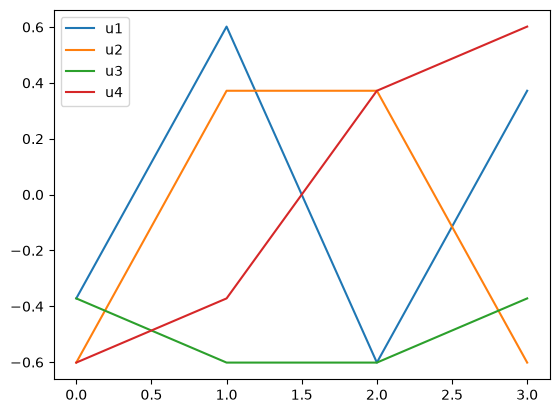

In [ ]:
from matplotlib.pyplot import plot, legend
plot(U)
legend(['u1','u2','u3','u4'])

In [8]:
print(matmul(K,U[:,0])/w[0])

[-0.37174803+0.j  0.60150096+0.j -0.60150096+0.j  0.37174803+0.j]


In [9]:
help(eig)

Help on _ArrayFunctionDispatcher in module numpy.linalg:

eig(a)
    Compute the eigenvalues and right eigenvectors of a square array.

    Parameters
    ----------
    a : (..., M, M) array
        Matrices for which the eigenvalues and right eigenvectors will
        be computed

    Returns
    -------
    A namedtuple with the following attributes:

    eigenvalues : (..., M) array
        The eigenvalues, each repeated according to its multiplicity.
        The eigenvalues are not necessarily ordered. The resulting
        array will be of complex type, unless the imaginary part is
        zero in which case it will be cast to a real type. When `a`
        is real the resulting eigenvalues will be real (0 imaginary
        part) or occur in conjugate pairs

    eigenvectors : (..., M, M) array
        The normalized (unit "length") eigenvectors, such that the
        column ``eigenvectors[:,i]`` is the eigenvector corresponding to the
        eigenvalue ``eigenvalues[i]``.

    R